**Simulation of Random Variables**

Consider an urn containing 3 red balls, 4 blue balls, and 2 black balls. We roll a die; if we obtain a prime number, we add one black ball to the urn. If we obtain a 6, we add one red ball, and in all other cases, we add one blue ball. Then, we draw one ball from the urn.

**a)** Simulate the experiment described above in Python.

**b)** Using the simulation, estimate the probability of drawing a red ball.

**c)** Calculate the theoretical probability of the event described above and compare it with the estimated probability obtained from the simulation.



## Step 1: Importing Libraries and Defining the Initial Urn

We will use NumPy to generate random numbers and simulate the experiment.

We will also use Matplotlib to visualize the results.

To ensure reproducibility, we will initialize the random number generator with a fixed seed.

The initial urn contains 3 red balls, 4 blue balls, and 2 black balls.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Seed for reproducibility
rng = np.random.default_rng(42)

# Define the initial urn
initial_urn = (
    ["Red"] * 3
    + ["Blue"] * 4
    + ["Black"] * 2
)

# Display the initial urn
print("Initial urn composition:")
print("Red balls:", initial_urn.count("Red"))
print("Blue balls:", initial_urn.count("Blue"))
print("Black balls:", initial_urn.count("Black"))
print("Total number of balls:", len(initial_urn))

Initial urn composition:
Red balls: 3
Blue balls: 4
Black balls: 2
Total number of balls: 9


## Step 2: Defining the Probabilistic Model

The experiment involves two random variables:

- **Die outcome:** An integer between 1 and 6.
- **Drawn ball color:** Red, blue, or black.

The die outcome determines which ball is added to the urn. The probability of drawing a red ball therefore depends on the result of the die.

The rules are implemented using conditional statements:

- If the die shows 6, a red ball is added.
- If the die shows 2, 3, or 5, a black ball is added.
- Otherwise, a blue ball is added.

We will define a Python function that performs one complete experiment.

In [2]:
def simulate_experiment(rng):
    # Create a new urn for each experiment
    urn = initial_urn.copy()

    # Roll the die
    die = rng.integers(1, 7)

    # Add a ball according to the die outcome
    if die == 6:
        urn.append("Red")
    elif die in [2, 3, 5]:
        urn.append("Black")
    else:
        urn.append("Blue")

    # Draw one ball randomly
    drawn_ball = rng.choice(urn)

    return die, drawn_ball

### Explanation

The function `simulate_experiment()` performs one complete experiment.

First, it creates a copy of the initial urn. Then, it rolls the die and adds the appropriate ball. Finally, it randomly selects one ball from the updated urn.

The function returns both the die outcome and the color of the drawn ball.

Creating a new urn for every experiment ensures that the initial conditions remain unchanged across simulations.

## Step 3: Simulation

In this step, we will simulate the random experiment and estimate the probability of drawing a red ball.

A single experiment is not sufficient to obtain a reliable probability estimate. Therefore, we will perform 100,000 independent simulations.

For each simulation, we will:

1. Start with the initial urn containing 3 red balls, 4 blue balls, and 2 black balls.
2. Roll a fair six-sided die.
3. Add a ball according to the outcome of the die.
4. Randomly draw one ball from the updated urn.
5. Record the color of the drawn ball.

After completing all simulations, we will count the number of times a red ball is drawn.

The experimental probability is estimated using the following formula:

$$
\widehat{P}(R)=
\frac{\text{Number of red balls drawn}}
{\text{Total number of simulations}}
$$

In [3]:
# Number of simulations
N = 100_000

# Store the results
die_results = np.empty(N, dtype=int)
drawn_colors = np.empty(N, dtype="<U5")

# Run the simulation
for i in range(N):
    die_results[i], drawn_colors[i] = simulate_experiment(rng)

# Count the drawn colors
red_count = np.sum(drawn_colors == "Red")
blue_count = np.sum(drawn_colors == "Blue")
black_count = np.sum(drawn_colors == "Black")

# Estimate the probability of drawing a red ball
p_experimental = red_count / N

print("Number of simulations:", N)
print("Red balls drawn:", red_count)
print("Blue balls drawn:", blue_count)
print("Black balls drawn:", black_count)

print(f"\nExperimental probability of drawing a red ball: {p_experimental:.6f}")
print(f"Experimental probability in percentage: {p_experimental * 100:.2f}%")

Number of simulations: 100000
Red balls drawn: 31599
Blue balls drawn: 43399
Black balls drawn: 25002

Experimental probability of drawing a red ball: 0.315990
Experimental probability in percentage: 31.60%


### Explanation

The simulation provides an estimate of the probability of drawing a red ball.

We calculate this estimate by dividing the number of times a red ball is drawn by the total number of experiments.

The estimated probability should be close to the theoretical probability. However, a small difference is expected because the simulation involves random outcomes.

Increasing the number of simulations generally improves the accuracy of the estimate.

## Step 4: Visualizing the Simulation Results

We will visualize the relative frequencies of the three possible outcomes.

A bar chart will show the proportion of red, blue, and black balls obtained during the simulation.

This visualization helps us understand the distribution of the observed results.

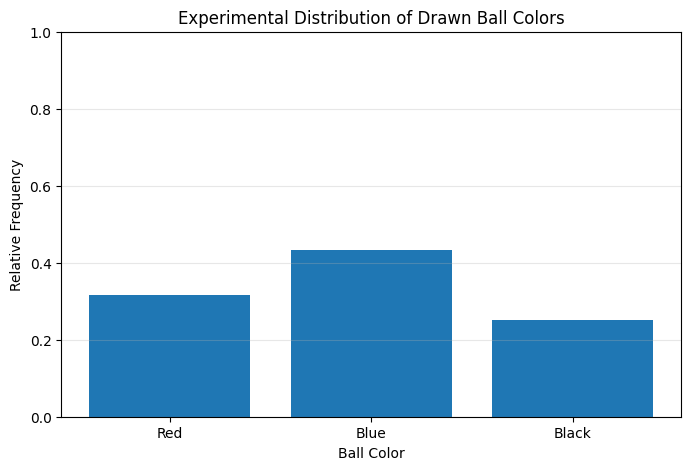

In [4]:
# Calculate relative frequencies
colors = ["Red", "Blue", "Black"]

relative_frequencies = [
    red_count / N,
    blue_count / N,
    black_count / N
]

# Plot the results
plt.figure(figsize=(8, 5))

plt.bar(colors, relative_frequencies)

plt.title("Experimental Distribution of Drawn Ball Colors")
plt.xlabel("Ball Color")
plt.ylabel("Relative Frequency")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

## Step 5: Calculating the Theoretical Probability

We can calculate the exact probability of drawing a red ball using the law of total probability.

There are three possible cases:

**Case 1: The die shows 1 or 4.**

A blue ball is added. The urn contains 3 red balls out of 10 balls.

$$
P(R \mid D \in \{1,4\}) = \frac{3}{10}
$$

The probability of this case is:

$$
P(D \in \{1,4\}) = \frac{2}{6}
$$

**Case 2: The die shows 2, 3, or 5.**

A black ball is added. The urn still contains 3 red balls out of 10 balls.

$$
P(R \mid D \in \{2,3,5\}) = \frac{3}{10}
$$

The probability of this case is:

$$
P(D \in \{2,3,5\}) = \frac{3}{6}
$$

**Case 3: The die shows 6.**

A red ball is added. The urn now contains 4 red balls out of 10 balls.

$$
P(R \mid D=6) = \frac{4}{10}
$$

The probability of this case is:

$$
P(D=6) = \frac{1}{6}
$$

Using the law of total probability:

$$
P(R) =
\frac{2}{6}\cdot\frac{3}{10}
+
\frac{3}{6}\cdot\frac{3}{10}
+
\frac{1}{6}\cdot\frac{4}{10}
$$

Therefore:

$$
P(R) = \frac{6}{60}+\frac{9}{60}+\frac{4}{60}
$$

The theoretical probability is:

$$
\boxed{P(R)=\frac{19}{60}\approx 0.316667}
$$

In percentage form:

$$
\boxed{P(R)\approx 31.67\%}
$$

In [5]:
from fractions import Fraction

# Calculate the exact theoretical probability
p_theoretical = (
    Fraction(2, 6) * Fraction(3, 10)
    + Fraction(3, 6) * Fraction(3, 10)
    + Fraction(1, 6) * Fraction(4, 10)
)

print("Exact theoretical probability:", p_theoretical)
print(f"Decimal probability: {float(p_theoretical):.6f}")
print(f"Percentage: {float(p_theoretical) * 100:.2f}%")

Exact theoretical probability: 19/60
Decimal probability: 0.316667
Percentage: 31.67%


### Interpretation

The theoretical probability of drawing a red ball is exactly \(19/60\), which is approximately 0.316667 or 31.67%.

This result is obtained analytically by considering all possible outcomes of the die and the corresponding probability of drawing a red ball in each case.

Unlike the experimental probability, the theoretical probability does not depend on random simulation.

## Step 6: Comparing Experimental and Theoretical Results

Finally, we will compare the probability estimated through Monte Carlo simulation with the theoretical probability.

We will calculate the absolute error as:

$$
\text{Absolute Error} =
\left|P_{\text{experimental}}-P_{\text{theoretical}}\right|
$$

We will also express the error in percentage points by multiplying the absolute error by 100.

A small error indicates that the simulation result is close to the theoretical value.

In [6]:
# Convert the theoretical probability to a decimal
p_theoretical_decimal = float(p_theoretical)

# Calculate the absolute error
absolute_error = abs(p_experimental - p_theoretical_decimal)

# Display the comparison
print(f"Experimental probability: {p_experimental:.6f}")
print(f"Theoretical probability:  {p_theoretical_decimal:.6f}")
print(f"Absolute error:           {absolute_error:.6f}")
print(f"Absolute error in percentage points: {absolute_error * 100:.4f}")

Experimental probability: 0.315990
Theoretical probability:  0.316667
Absolute error:           0.000677
Absolute error in percentage points: 0.0677


### Interpretation of the Results

The experimental probability is obtained from the simulation, whereas the theoretical probability is calculated mathematically.

The theoretical probability of drawing a red ball is approximately 0.316667, or 31.67%.

The absolute error measures the difference between the experimental and theoretical probabilities.

If the error is small, the simulation provides a good approximation of the theoretical result.

Small differences are expected because the simulation is based on random outcomes. Increasing the number of simulations generally reduces the variability of the estimated probability.

Therefore, comparing both values allows us to evaluate how accurately the simulation represents the theoretical model.